In [2]:
import numpy as np
import matplotlib.pyplot as plt

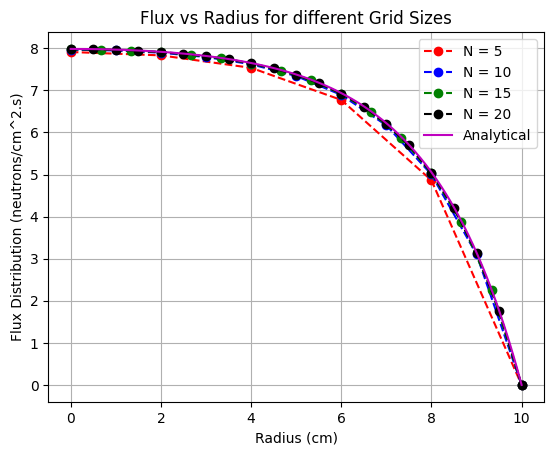

5 0.19150877835179347
10 0.0518140748999425
15 0.023401268068919734
20 0.013239026444111346


In [17]:
def flux_dist(N, R=10, D=0.3543, sigma_a=0.121):
    dR = R/N
    radius = np.linspace(0, R, N+1)
    mat = np.zeros([N+1, N+1])
    c = np.full(N+1, -1.0/D)

    for i in range(N+1):
        if i == 0:
            mat[0,0] = -6/dR**2 - sigma_a/D
            mat[0,1] =  6/dR**2
        elif i == N:
            mat[N,N] = 1
            c[N] = 0
        if(i != 0 and i != N):
            mat[i, i-1] = (1/dR**2 - 1/(radius[i]*dR))
            mat[i,i] = -(2/dR**2 + sigma_a/D)
            mat[i, i+1] = (1/dR**2 + 1/(radius[i]*dR))

    flux = np.linalg.solve(mat, c)
    return flux, radius, mat

D = 0.3543
sigma_a = 0.121
R =10

L = np.sqrt(D/sigma_a)
rf = np.linspace(1e-6, R, 500)
exact = (1/sigma_a)*(1 - (R/rf)*np.sinh(rf/L)/np.sinh(R/L))

flux_1, radius_1, mat_1 = flux_dist(5)
flux_2, radius_2, mat_2 = flux_dist(10)
flux_3, radius_3, mat_3 = flux_dist(15)
flux_4, radius_4, mat_4 = flux_dist(20)

plt.plot(radius_1, flux_1, 'ro--', label='N = 5')
plt.plot(radius_2, flux_2, 'bo--', label='N = 10')
plt.plot(radius_3, flux_3, 'go--', label='N = 15')
plt.plot(radius_4, flux_4, 'ko--', label='N = 20')
plt.plot(rf, exact, 'm-', label='Analytical')
plt.ylabel("Flux Distribution (neutrons/cm^2.s)")
plt.xlabel("Radius (cm)")
plt.title("Flux vs Radius for different Grid Sizes")
plt.grid()
plt.legend()
plt.show()

for N in [5, 10, 15, 20]:
    phi, r, mat = flux_dist(N) 
    ex = (1/sigma_a)*(1 - (R/r[1:])*np.sinh(r[1:]/L)/np.sinh(R/L))
    print(N, np.max(np.abs(phi[1:] - ex)))

k at grid size N= 5 1.1957427107221683 error in k:  0.008704407755426358
k at grid size N= 8 1.1904506504452772 error in k:  0.0034123474785352492
k at grid size N= 12 1.1885568183812705 error in k:  0.0015185154145285207
k at grid size N= 16 1.1878928443181809 error in k:  0.00085454135143892


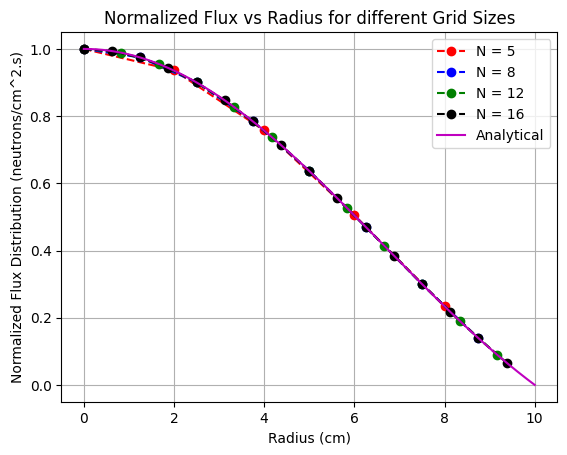

nuSigmaF value is  0.15585580878405367


In [33]:
def k_dist(N, nuSigmaF, R=10, D=0.3543, sigma_a=0.121):
    dR = R/N
    radius = np.linspace(0, R, N+1)
    mat = np.zeros([N+1, N+1])

    for i in range(N+1):
        if i == 0:
            mat[0,0] = -6/dR**2 - sigma_a/D
            mat[0,1] =  6/dR**2
        elif i == N:
            mat[N,N] = 1
        if(i != 0 and i != N):
            mat[i, i-1] = (1/dR**2 - 1/(radius[i]*dR))
            mat[i,i] = -(2/dR**2 + sigma_a/D)
            mat[i, i+1] = (1/dR**2 + 1/(radius[i]*dR))

    mat = mat[:N, :N]
    vals, vecs = np.linalg.eig(-mat)
    idx = np.argmin(vals.real)
    lam = vals[idx].real
    k = nuSigmaF / (D * lam)

    flux = np.abs(vecs[:, idx].real)
    flux = flux / flux.max() 
    return k, flux, radius[:N]

k1, flux_1, radius_1 = k_dist(5, 0.18514)
k2, flux_2, radius_2 = k_dist(8, 0.18514)
k3, flux_3, radius_3 = k_dist(12, 0.18514)
k4, flux_4, radius_4 = k_dist(16, 0.18514)

rf = np.linspace(1e-6, R, 500)
exact = np.sin(np.pi*rf/R) / rf
exact = exact / exact.max()
k_analytial = 0.18514/(sigma_a + D*(np.pi/R)**2)

print("k at grid size N= 5", k1, "error in k: ", abs(k1-k_analytial))
print("k at grid size N= 8", k2, "error in k: ", abs(k2-k_analytial))
print("k at grid size N= 12", k3, "error in k: ", abs(k3-k_analytial))
print("k at grid size N= 16", k4, "error in k: ", abs(k4-k_analytial))

plt.plot(radius_1, flux_1, 'ro--', label='N = 5')
plt.plot(radius_2, flux_2, 'bo--', label='N = 8')
plt.plot(radius_3, flux_3, 'go--', label='N = 12')
plt.plot(radius_4, flux_4, 'ko--', label='N = 16')
plt.plot(rf, exact, 'm-', label='Analytical')
plt.ylabel("Normalized Flux Distribution (neutrons/cm^2.s)")
plt.xlabel("Radius (cm)")
plt.title("Normalized Flux vs Radius for different Grid Sizes")
plt.grid()
plt.legend()
plt.show()

low, high = 0.10, 0.25

for _ in range(50):
    mid = (low+high)/2.0
    k_cal, flux, r = k_dist(16, mid)
    if(k_cal < 1):
        low = mid
    elif(k_cal == 1):
        print("nuSigmaF for criticality is ", mid)
    else:
        high = mid

print("nuSigmaF value is ", mid)

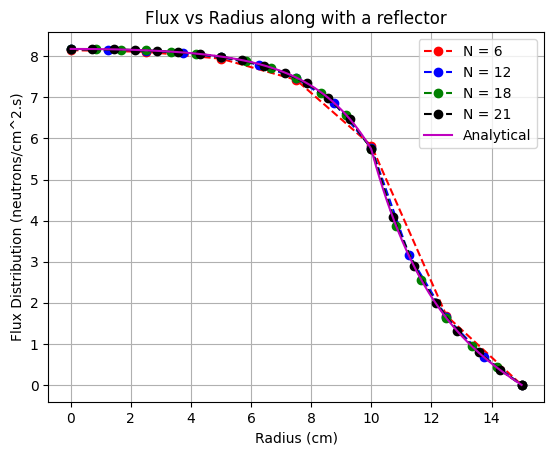

In [47]:
def flux_dist_reflector(N, R=15, Dc=0.3543, Dr = 0.16, sigma_ac=0.121, sigma_ar=0.0197):
    dR = R/N
    radius = np.linspace(0, R, N+1)
    mat = np.zeros([N+1, N+1])
    c = np.zeros([N+1])

    for i in range(N+1):
        if i == 0:
            c[0] = -1.0/Dc
            mat[0,0] = -6/dR**2 - sigma_ac/Dc
            mat[0,1] =  6/dR**2
        elif(i != 0 and i < (2*N)/3):
            c[i] = -1.0/Dc
            mat[i, i-1] = (1/dR**2 - 1/(radius[i]*dR))
            mat[i,i] = -(2/dR**2 + sigma_ac/Dc)
            mat[i, i+1] = (1/dR**2 + 1/(radius[i]*dR))
        elif(i == 2*N/3):
            c[i] = -1.0*((10**3 - (10-dR/2)**3)/3)
            mat[i, i-1] = Dc*(10-dR/2)**2/dR
            mat[i, i+1] = Dr*(10+dR/2)**2/dR
            mat[i, i] = -(mat[i, i-1] + mat[i, i+1]) - sigma_ac*(10**3 - (10-dR/2)**3)/3 - sigma_ar*((10+dR/2)**3 - 10**3)/3
        elif(i != N and i > (2*N)/3):
            c[i] = 0
            mat[i, i-1] = (1/dR**2 - 1/(radius[i]*dR))
            mat[i,i] = -(2/dR**2 + sigma_ar/Dr)
            mat[i, i+1] = (1/dR**2 + 1/(radius[i]*dR))
        elif(i == N):
            mat[N, N] = 1
    
    flux = np.linalg.solve(mat, c)
    return flux, radius, mat

flux_1t, radius_1t, mat_1t = flux_dist_reflector(6)
flux_2t, radius_2t, mat_2t = flux_dist_reflector(12)
flux_3t, radius_3t, mat_3t = flux_dist_reflector(18)
flux_4t, radius_4t, mat_4t = flux_dist_reflector(21)

Rc, T, Rt = 10.0, 5.0, 15.0
Dc, Sac, Dr, Sar, S = 0.3543, 0.121, 0.16, 0.0197, 1.0
Lc, Lr = np.sqrt(Dc/Sac), np.sqrt(Dr/Sar)

a11 =  np.sinh(Rc/Lc)/Rc
a12 = -np.sinh(T/Lr)/Rc
a21 =  Dc*(np.cosh(Rc/Lc)/(Lc*Rc) - np.sinh(Rc/Lc)/Rc**2)
a22 =  Dr*(np.cosh(T/Lr)/(Lr*Rc) + np.sinh(T/Lr)/Rc**2)
A, C = np.linalg.solve([[a11, a12], [a21, a22]], [-S/Sac, 0.0])

rf = np.linspace(1e-6, Rt, 600)
exact = np.where(rf <= Rc, S/Sac + A*np.sinh(rf/Lc)/rf,
                 C*np.sinh((Rt - rf)/Lr)/rf)

plt.plot(radius_1t, flux_1t, 'ro--', label='N = 6')
plt.plot(radius_2t, flux_2t, 'bo--', label='N = 12')
plt.plot(radius_3t, flux_3t, 'go--', label='N = 18')
plt.plot(radius_4t, flux_4t, 'ko--', label='N = 21')
plt.plot(rf, exact, 'm-', label='Analytical')
plt.ylabel("Flux Distribution (neutrons/cm^2.s)")
plt.xlabel("Radius (cm)")
plt.title("Flux vs Radius along with a reflector")
plt.grid()
plt.legend()
plt.show()



k at grid size N=6 is  1.347402986608243 and the error is : 0.011868369311090365
k at grid size N=9 is  1.3536326905395653 and the error is : 0.005638665379768204
k at grid size N=12 is  1.356016158603764 and the error is : 0.003255197315569447
k at grid size N=18 is  1.3577934928168016 and the error is : 0.00147786310253184


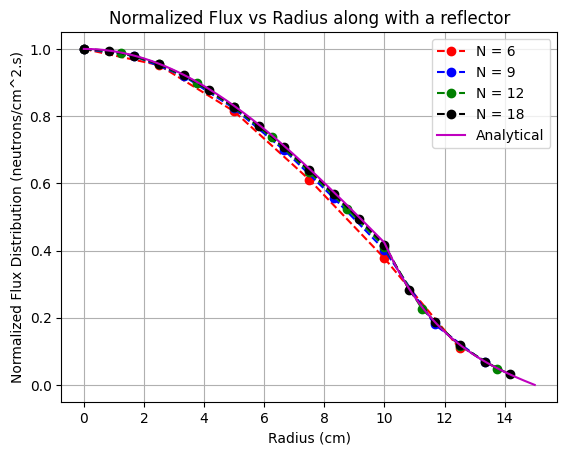

nuSigmaF value is  0.13635357731455852


In [9]:
def k_dist_reflector(N, nuSigmaF, R=15, Dc=0.3543, Dr = 0.16, sigma_ac=0.121, sigma_ar=0.0197):
    dR = R/N
    radius = np.linspace(0, R, N+1)
    mat = np.zeros([N+1, N+1])
    c = np.zeros([N+1])

    for i in range(N+1):
        if i == 0:
            c[0] = -1.0/Dc
            mat[0,0] = -6/dR**2 - sigma_ac/Dc
            mat[0,1] =  6/dR**2
        elif(i != 0 and i < (2*N)/3):
            c[i] = -1.0/Dc
            mat[i, i-1] = (1/dR**2 - 1/(radius[i]*dR))
            mat[i,i] = -(2/dR**2 + sigma_ac/Dc)
            mat[i, i+1] = (1/dR**2 + 1/(radius[i]*dR))
        elif(i == 2*N/3):
            Vc = (10**3-(10-dR/2)**3)/3; Vr = ((10+dR/2)**3-10**3)/3
            c[i] = -Vc
            mat[i,i-1] = Dc*(10-dR/2)**2/dR
            mat[i,i+1] = Dr*(10+dR/2)**2/dR
            mat[i,i] = -(mat[i,i-1]+mat[i,i+1]) - sigma_ac*Vc - sigma_ar*Vr
        elif(i != N and i > (2*N)/3):
            c[i] = 0
            mat[i, i-1] = (1/dR**2 - 1/(radius[i]*dR))
            mat[i,i] = -(2/dR**2 + sigma_ar/Dr)
            mat[i, i+1] = (1/dR**2 + 1/(radius[i]*dR))
        elif(i == N):
            mat[N, N] = 1
    
    mat = mat[:N, :N]
    F = np.diag(nuSigmaF*-c[:N])        
    vals, vecs = np.linalg.eig(np.linalg.solve(-mat, F))
    i = np.argmax(vals.real)        
    phi = np.abs(vecs[:, i].real); phi /= phi.max()
    return vals[i].real, phi, radius[:N]

k1t, flux_1t, radius_1t = k_dist_reflector(6, 0.18514)
k2t, flux_2t, radius_2t = k_dist_reflector(9, 0.18514)
k3t, flux_3t, radius_3t = k_dist_reflector(12, 0.18514)
k4t, flux_4t, radius_4t = k_dist_reflector(18, 0.18514)

Dc, Sac, Dr, Sar = 0.3543, 0.121, 0.16, 0.0197
Rc, T = 10.0, 5.0
Rt = 15.0
kap = np.sqrt(Sar/Dr)

def func(B):
    return Dc*(B/np.tan(B*Rc) - 1/Rc) + Dr*(kap/np.tanh(kap*T) + 1/Rc)

low, high = np.pi/(2*Rc) + 1e-6, np.pi/Rc - 1e-6
for _ in range(60):
    mid = 0.5*(low + high)
    if func(mid) > 0:
        low = mid
    else:
        high = mid
B = mid
k_exact = 0.18514 / (Sac + Dc*B**2)

print("k at grid size N=6 is ", k1t, "and the error is :", abs(k1t- k_exact))
print("k at grid size N=9 is ", k2t, "and the error is :", abs(k2t- k_exact))
print("k at grid size N=12 is ", k3t, "and the error is :", abs(k3t- k_exact))
print("k at grid size N=18 is ", k4t, "and the error is :", abs(k4t- k_exact))

rf = np.linspace(1e-6, Rt, 600)
Cc  = np.sin(B*Rc)/np.sinh(kap*T)
phi = np.where(rf <= Rc, np.sin(B*rf)/rf, Cc*np.sinh(kap*(Rt - rf))/rf)
phi = phi/phi.max()

plt.plot(radius_1t, flux_1t, 'ro--', label='N = 6')
plt.plot(radius_2t, flux_2t, 'bo--', label='N = 9')
plt.plot(radius_3t, flux_3t, 'go--', label='N = 12')
plt.plot(radius_4t, flux_4t, 'ko--', label='N = 18')
plt.plot(rf, phi, 'm-', label='Analytical')
plt.ylabel("Normalized Flux Distribution (neutrons/cm^2.s)")
plt.xlabel("Radius (cm)")
plt.title("Normalized Flux vs Radius along with a reflector")
plt.grid()
plt.legend()
plt.show()

low, high = 0.10, 0.25

for _ in range(50):
    mid = (low+high)/2.0
    k_cal, flux, r = k_dist_reflector(18, mid)
    if(k_cal < 1):
        low = mid
    elif(k_cal == 1):
        print("nuSigmaF for criticality is ", mid)
    else:
        high = mid

print("nuSigmaF value is ", mid)